# Dataset 3 for analysis/demonstration

## Part 1: Test set (10%) MSE Comparsion for 30% (aug), 60%(non-aug/"true"), 90%(all training)

In [1]:
from sklearn.datasets import load_diabetes
X, y = load_diabetes(return_X_y=True)
X[:10], y[:10]

(array([[ 0.03807591,  0.05068012,  0.06169621,  0.02187239, -0.0442235 ,
         -0.03482076, -0.04340085, -0.00259226,  0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, -0.02632753, -0.00844872,
         -0.01916334,  0.07441156, -0.03949338, -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, -0.00567042, -0.04559945,
         -0.03419447, -0.03235593, -0.00259226,  0.00286131, -0.02593034],
        [-0.08906294, -0.04464164, -0.01159501, -0.03665608,  0.01219057,
          0.02499059, -0.03603757,  0.03430886,  0.02268774, -0.00936191],
        [ 0.00538306, -0.04464164, -0.03638469,  0.02187239,  0.00393485,
          0.01559614,  0.00814208, -0.00259226, -0.03198764, -0.04664087],
        [-0.09269548, -0.04464164, -0.04069594, -0.01944183, -0.06899065,
         -0.07928784,  0.04127682, -0.0763945 , -0.04117617, -0.09634616],
        [-0.04547248,  0.05068012, -0.04716281, -0.01599898, -0.04009564,
         -0.02480001,  0.0007788

In [2]:
from sklearn.model_selection import train_test_split
import torch
from crda_gp.utils import set_seed

set_seed(42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# Turn the data splits into torch.Tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [3]:
import gpytorch
from crda_gp.models import ARDExactGPModel_Dense
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Dense(train_x=X_train_tensor,
                              train_y=y_train_tensor,
                              likelihood=likelihood)
model

ARDExactGPModel_Dense(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (mean_module): ConstantMean()
  (covar_module): ScaleKernel(
    (base_kernel): RBFKernel(
      (raw_lengthscale_constraint): Positive()
    )
    (raw_outputscale_constraint): Positive()
  )
)

In [4]:
from crda_gp.utils import train_step
set_seed(42)
train_step(X_train=X_train_tensor,
           y_train=y_train_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1334.407 | Noise: 1.281
Iter: 20/100 | Loss: 850.412 | Noise: 1.897
Iter: 30/100 | Loss: 660.854 | Noise: 2.414
Iter: 40/100 | Loss: 560.419 | Noise: 2.824
Iter: 50/100 | Loss: 494.697 | Noise: 3.156
Iter: 60/100 | Loss: 452.005 | Noise: 3.434
Iter: 70/100 | Loss: 420.327 | Noise: 3.680
Iter: 80/100 | Loss: 395.144 | Noise: 3.905
Iter: 90/100 | Loss: 374.254 | Noise: 4.115
Iter: 100/100 | Loss: 356.449 | Noise: 4.313


In [5]:
from crda_gp.utils import val_step
set_seed(42)
y_pred = val_step(X_test=X_test_tensor,
                  model=model,
                  likelihood=likelihood)

In [6]:
from sklearn.metrics import mean_squared_error
set_seed(42)
MSE = mean_squared_error(y_true=y_test_tensor, 
                         y_pred=y_pred)

In [7]:
MSE

2332.317626953125

In [8]:
# Splitting the train data into augment and true values respectively
X_train_aug, X_train_true, y_train_aug, y_train_true = train_test_split(X_train, y_train, test_size=(0.6*len(X)/len(X_train)), random_state=42)
# Change the data into tensors
X_train_aug_tensor = torch.tensor(X_train_aug, dtype=torch.float32)
X_train_true_tensor = torch.tensor(X_train_true, dtype=torch.float32)
y_train_aug_tensor = torch.tensor(y_train_aug, dtype=torch.float32)
y_train_true_tensor = torch.tensor(y_train_true, dtype=torch.float32)

In [9]:
likelihood_true = gpytorch.likelihoods.GaussianLikelihood()
model_true = ARDExactGPModel_Dense(train_x=X_train_true_tensor,
                                   train_y=y_train_true_tensor,
                                   likelihood=likelihood_true)

In [10]:
train_step(X_train=X_train_true_tensor, 
           y_train=y_train_true_tensor,
           model=model_true,
           likelihood=likelihood_true)

Iter: 10/100 | Loss: 1318.870 | Noise: 1.280
Iter: 20/100 | Loss: 836.023 | Noise: 1.891
Iter: 30/100 | Loss: 651.611 | Noise: 2.403
Iter: 40/100 | Loss: 550.527 | Noise: 2.807
Iter: 50/100 | Loss: 487.783 | Noise: 3.129
Iter: 60/100 | Loss: 445.909 | Noise: 3.401
Iter: 70/100 | Loss: 414.723 | Noise: 3.641
Iter: 80/100 | Loss: 389.722 | Noise: 3.861
Iter: 90/100 | Loss: 368.957 | Noise: 4.066
Iter: 100/100 | Loss: 351.282 | Noise: 4.261


In [11]:
y_pred_true = val_step(X_test=X_test_tensor, 
                       model=model_true, 
                       likelihood=likelihood_true)

In [12]:
MSE_true = mean_squared_error(y_test_tensor, y_pred_true)
MSE_true

2696.030517578125

In [13]:
MSE

2332.317626953125

In [14]:
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Dense(train_x=X_train_aug_tensor, 
                                  train_y=y_train_aug_tensor, 
                                  likelihood=likelihood_aug)

In [15]:
train_step(X_train=X_train_aug_tensor, 
           y_train=y_train_aug_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 1665.515 | Noise: 1.275
Iter: 20/100 | Loss: 1023.593 | Noise: 1.864
Iter: 30/100 | Loss: 790.150 | Noise: 2.342
Iter: 40/100 | Loss: 674.475 | Noise: 2.710
Iter: 50/100 | Loss: 598.731 | Noise: 3.006
Iter: 60/100 | Loss: 547.946 | Noise: 3.260
Iter: 70/100 | Loss: 509.672 | Noise: 3.490
Iter: 80/100 | Loss: 479.087 | Noise: 3.701
Iter: 90/100 | Loss: 453.541 | Noise: 3.899
Iter: 100/100 | Loss: 431.251 | Noise: 4.086


In [16]:
y_pred_aug = val_step(X_test=X_test_tensor, 
                      model=model_aug, 
                      likelihood=likelihood_aug)

In [17]:
MSE_aug = mean_squared_error(y_test_tensor, y_pred_aug)
MSE_aug

2345.467529296875

In [18]:
MSE

2332.317626953125

In [19]:
import pandas as pd
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_train_aug_tensor))
    y_new_aug = pred_dist.mean

residual = y_train_aug_tensor - y_new_aug
corr = abs(pd.DataFrame(X_train).corrwith(pd.Series(residual)))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
preturb_idx

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


array([9, 3, 0, 8, 1, 6])

In [20]:
corr

0    0.040963
1    0.018708
2    0.084910
3    0.053953
4    0.095780
5    0.124966
6    0.017853
7    0.132507
8    0.038293
9    0.062535
dtype: float64

In [21]:
from crda_gp.crda import CRDA_function
X_train_aug_CRDA_tensor, y_train_aug_CRDA_tensor, _, _ = CRDA_function(X_train_aug_tensor, 
                                                                 y_train_aug_tensor, 
                                                                 model=model_aug, 
                                                                 likelihood=likelihood, 
                                                                 perturb_idx=preturb_idx, 
                                                                 p=0.005,
                                                                 )

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [22]:
likelihood_aug_new = gpytorch.likelihoods.GaussianLikelihood()
model_aug_new = ARDExactGPModel_Dense(train_x=X_train_aug_CRDA_tensor, 
                                      train_y=y_train_aug_CRDA_tensor, 
                                      likelihood=likelihood_aug_new)

In [23]:
train_step(X_train=X_train_aug_CRDA_tensor, 
           y_train=y_train_aug_CRDA_tensor,
           model=model_aug_new,
           likelihood=likelihood_aug_new)

Iter: 10/100 | Loss: 1461.592 | Noise: 1.278
Iter: 20/100 | Loss: 877.457 | Noise: 1.875
Iter: 30/100 | Loss: 647.267 | Noise: 2.341
Iter: 40/100 | Loss: 548.575 | Noise: 2.668
Iter: 50/100 | Loss: 484.046 | Noise: 2.918
Iter: 60/100 | Loss: 434.966 | Noise: 3.127
Iter: 70/100 | Loss: 402.309 | Noise: 3.303
Iter: 80/100 | Loss: 377.057 | Noise: 3.460
Iter: 90/100 | Loss: 356.163 | Noise: 3.605
Iter: 100/100 | Loss: 338.469 | Noise: 3.741


In [24]:
y_pred_aug_new = val_step(X_test=X_test_tensor, 
                      model=model_aug_new, 
                      likelihood=likelihood_aug_new)

In [25]:
MSE_aug_new = mean_squared_error(y_test_tensor, y_pred_aug_new)
MSE_aug_new

2239.649169921875

In [26]:
MSE_aug

2345.467529296875

In [27]:
MSE_true

2696.030517578125

In [28]:
MSE

2332.317626953125

In [29]:
MSE_true_percentage = ((MSE_true - MSE)/MSE)*100
MSE_true_percentage

15.594483633866988

In [30]:
MSE_aug_percentage = ((MSE_aug - MSE)/MSE)*100
MSE_aug_percentage

0.5638126725015866

In [31]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE)/MSE)*100
MSE_aug_new_percentage

-3.9732348613387405

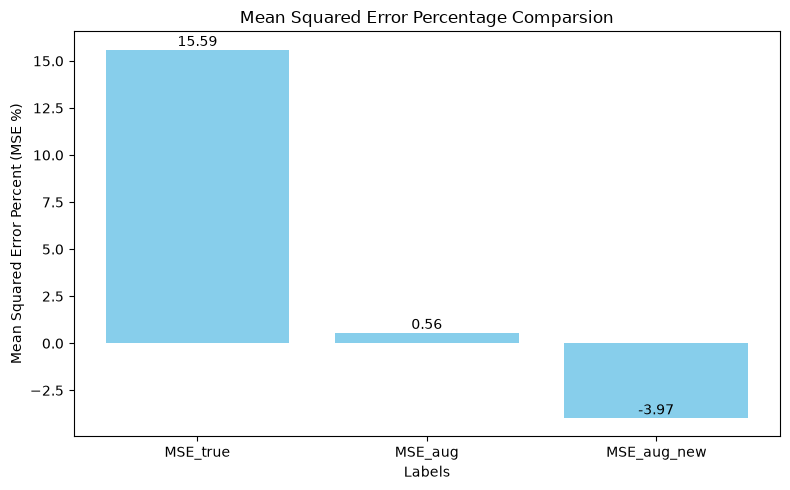

In [32]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_true', 'MSE_aug', 'MSE_aug_new']
MSE_results_values = [MSE_true_percentage, MSE_aug_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Part 2: Informative metric testing

In [33]:
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

In [34]:
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Dense(train_x=X_tensor,
                              train_y=y_tensor,
                              likelihood=likelihood)

In [35]:
set_seed(42)
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1306.059 | Noise: 1.281
Iter: 20/100 | Loss: 826.212 | Noise: 1.896
Iter: 30/100 | Loss: 640.069 | Noise: 2.410
Iter: 40/100 | Loss: 542.487 | Noise: 2.816
Iter: 50/100 | Loss: 480.593 | Noise: 3.144
Iter: 60/100 | Loss: 439.244 | Noise: 3.420
Iter: 70/100 | Loss: 408.756 | Noise: 3.665
Iter: 80/100 | Loss: 384.352 | Noise: 3.890
Iter: 90/100 | Loss: 364.063 | Noise: 4.101
Iter: 100/100 | Loss: 346.774 | Noise: 4.300


In [36]:
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_train=X_tensor,
                                             y_train=y_tensor,
                                             model=model,
                                             likelihood=likelihood)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83


Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
Iter: 109
Iter: 110
Iter: 111
Iter: 112
Iter: 113
Iter: 114
Iter: 115
Iter: 116
Iter: 117
Iter: 118
Iter: 119
Iter: 120
Iter: 121
Iter: 122
Iter: 123
Iter: 124
Iter: 125
Iter: 126
Iter: 127
Iter: 128
Iter: 129
Iter: 130
Iter: 131
Iter: 132
Iter: 133
Iter: 134
Iter: 135
Iter: 136
Iter: 137
Iter: 138
Iter: 139
Iter: 140
Iter: 141
Iter: 142
Iter: 143
Iter: 144
Iter: 145
Iter: 146
Iter: 147
Iter: 148
Iter: 149
Iter: 150
Iter: 151
Iter: 152
Iter: 153
Iter: 154
Iter: 155
Iter: 156
Iter: 157
Iter: 158
Iter: 159
Iter: 160
Iter: 161
Iter: 162
Iter: 163
Iter: 164
Iter: 165
Iter: 166
Iter: 167
Iter: 168
Iter: 169
Iter: 170
Iter: 171
Iter: 172
Iter: 173
Iter: 174
Iter: 175
Iter: 176
Iter: 177
Iter: 178
Iter: 179
Iter: 180
Iter: 181
Iter: 182
Iter: 183
Iter: 184
Iter: 

In [37]:
from crda_gp.utils import entropy_cal
entropies_true = entropy_cal(X=X_tensor)

In [38]:
entropies_aug = entropy_cal(X=X_CRDA_tensor)

Mean of True vs Aug: 2.629171934474823 | 2.6292282804384923


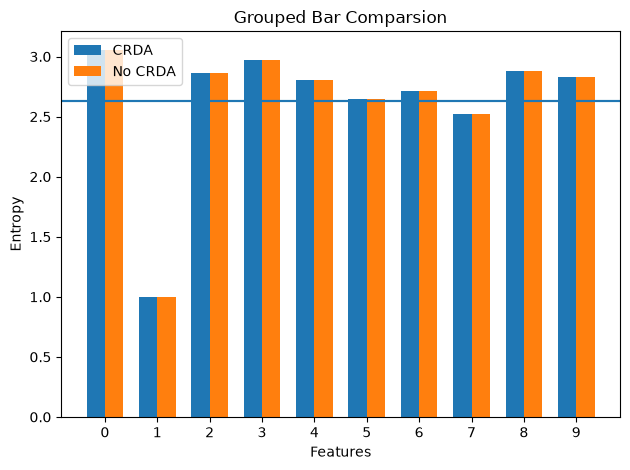

In [39]:
from crda_gp.utils import plot_comparsion_entropies
plot_comparsion_entropies(X_tensor,
                          entropy_1=entropies_aug,
                          entropy_2=entropies_true)

## Part 3: Random Benchmarking vs CRDA

In [40]:
from crda_gp.crda import random_benchmark
X_random_tensor, y_random_tensor = random_benchmark(X_train=X_train_aug_tensor,
                                                    y_train=y_train_aug_tensor,
                                                    model=model_aug,
                                                    likelihood=likelihood_aug,
                                                    perturb_idx=preturb_idx,
                                                    p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [41]:
set_seed(42)
likelihood_random = gpytorch.likelihoods.GaussianLikelihood()
model_random = ARDExactGPModel_Dense(train_x=X_random_tensor,
                                     train_y=y_random_tensor,
                                     likelihood=likelihood_random)

In [42]:
set_seed(42)
train_step(X_train=X_random_tensor,
           y_train=y_random_tensor,
           model=model_random,
           likelihood=likelihood_random)

Iter: 10/100 | Loss: 891.264 | Noise: 1.275
Iter: 20/100 | Loss: 525.966 | Noise: 1.863
Iter: 30/100 | Loss: 401.378 | Noise: 2.333
Iter: 40/100 | Loss: 346.858 | Noise: 2.691
Iter: 50/100 | Loss: 308.158 | Noise: 2.979
Iter: 60/100 | Loss: 282.766 | Noise: 3.228
Iter: 70/100 | Loss: 263.138 | Noise: 3.453
Iter: 80/100 | Loss: 247.519 | Noise: 3.661
Iter: 90/100 | Loss: 234.416 | Noise: 3.855
Iter: 100/100 | Loss: 222.823 | Noise: 4.040


In [43]:
set_seed(42)
y_pred_aug_rand_new = val_step(X_test=X_test_tensor.float(), 
                              model=model_random, 
                              likelihood=likelihood_random)

In [44]:
MSE_aug_rand_new = mean_squared_error(y_test_tensor, y_pred_aug_rand_new)
MSE_aug_rand_new

2316.545654296875

In [45]:
MSE_aug_new


2239.649169921875

In [46]:
MSE_aug

2345.467529296875

In [47]:
MSE

2332.317626953125

In [48]:
MSE_aug_rand_new_percentage = ((MSE_aug_rand_new - MSE_aug)/MSE_aug) * 100
MSE_aug_rand_new_percentage

-1.2330963715652123

In [49]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE_aug)/MSE_aug) * 100
MSE_aug_new_percentage

-4.5116105020956

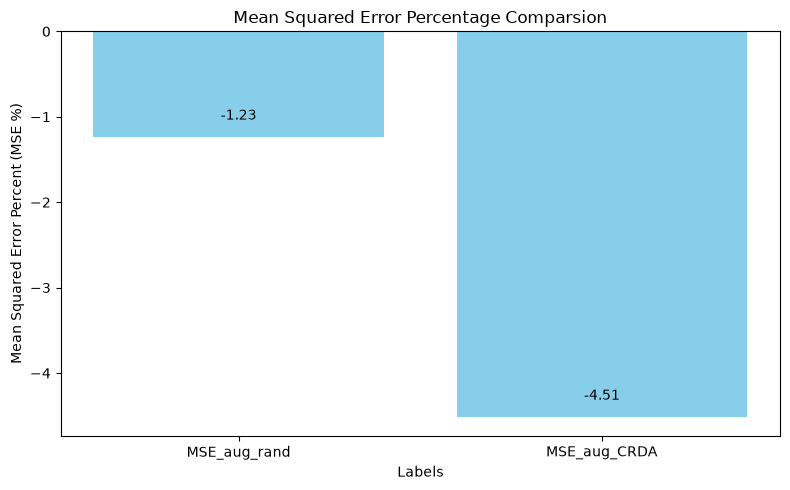

In [50]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_aug_rand', 'MSE_aug_CRDA']
MSE_results_values = [MSE_aug_rand_new_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()